In [1]:
import sys
from pathlib import Path
from huggingface_hub import hf_hub_download
import zipfile
import pandas as pd

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import clean_phrasebank_dataframe, load_phrasebank_from_hub


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
zip_path = hf_hub_download(
    repo_id="takala/financial_phrasebank",
    repo_type="dataset",
    filename="data/FinancialPhraseBank-v1.0.zip"
)

with zipfile.ZipFile(zip_path) as archive:
    file_name = "FinancialPhraseBank-v1.0/Sentences_50Agree.txt"

    rows = []
    for line in archive.read(file_name).decode("latin-1").splitlines():
        sentence, label = line.rsplit("@", 1)
        rows.append(
            {
                "sentence": sentence.strip(),
                "label": label.strip()
            }
        )

phrasebank_df = pd.DataFrame(rows)

print(phrasebank_df.head())
print("\nLabel counts:")
print(phrasebank_df["label"].value_counts())
print(f"\nTotal examples: {len(phrasebank_df)}")

                                            sentence     label
0  According to Gran , the company has no plans t...   neutral
1  Technopolis plans to develop in stages an area...   neutral
2  The international electronic industry company ...  negative
3  With the new production plant the company woul...  positive
4  According to the company 's updated strategy f...  positive

Label counts:
label
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Total examples: 4846


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sarth\.cache\huggingface\hub\datasets--takala--financial_phrasebank. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [3]:
print("Dataset shape:", phrasebank_df.shape)
print("\nMissing values:")
print(phrasebank_df.isna().sum())

print("\nExact duplicate rows:", phrasebank_df.duplicated().sum())
print(
    "Duplicate sentences:",
    phrasebank_df.duplicated(subset="sentence").sum()
)

print("\nLabels:")
print(sorted(phrasebank_df["label"].unique()))

Dataset shape: (4846, 2)

Missing values:
sentence    0
label       0
dtype: int64

Exact duplicate rows: 6
Duplicate sentences: 8

Labels:
['negative', 'neutral', 'positive']


In [4]:
from pathlib import Path

phrasebank_raw = phrasebank_df.copy()

phrasebank_clean = phrasebank_df.dropna(
    subset=["sentence", "label"]
).copy()

phrasebank_clean["sentence"] = (
    phrasebank_clean["sentence"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

phrasebank_clean["label"] = phrasebank_clean["label"].str.strip().str.lower()

phrasebank_clean = phrasebank_clean.drop_duplicates().reset_index(drop=True)

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw"
processed_dir = project_root / "data" / "processed"

raw_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

phrasebank_raw.to_csv(
    raw_dir / "financial_phrasebank_50agree_raw.csv",
    index=False
)

phrasebank_clean.to_csv(
    processed_dir / "financial_phrasebank_50agree_clean.csv",
    index=False
)

print(f"Clean dataset shape: {phrasebank_clean.shape}")
print(f"Saved raw data to: {raw_dir}")
print(f"Saved cleaned data to: {processed_dir}")

Clean dataset shape: (4840, 2)
Saved raw data to: c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\data\raw
Saved cleaned data to: c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\data\processed


          count  percentage
label                      
negative    604       12.48
neutral    2873       59.36
positive   1363       28.16


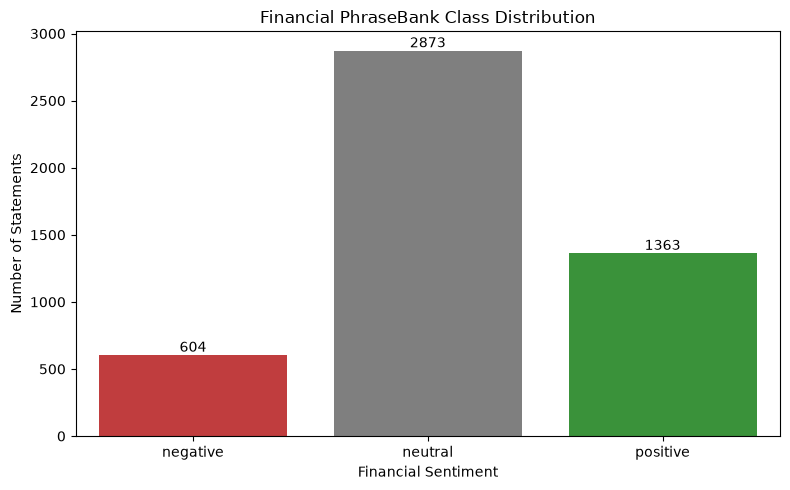

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

label_order = ["negative", "neutral", "positive"]

label_counts = (
    phrasebank_clean["label"]
    .value_counts()
    .reindex(label_order)
)

label_percentages = (label_counts / len(phrasebank_clean) * 100).round(2)

print(
    pd.DataFrame(
        {
            "count": label_counts,
            "percentage": label_percentages
        }
    )
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=phrasebank_clean,
    x="label",
    order=label_order,
    hue="label",
    palette={
        "negative": "#d62728",
        "neutral": "#7f7f7f",
        "positive": "#2ca02c"
    },
    legend=False
)

plt.title("Financial PhraseBank Class Distribution")
plt.xlabel("Financial Sentiment")
plt.ylabel("Number of Statements")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [6]:
phrasebank_clean["word_count"] = (
    phrasebank_clean["sentence"]
    .str.findall(r"\b\w+\b")
    .str.len()
)

print(phrasebank_clean["word_count"].describe())

for label in label_order:
    print(f"\n--- {label.upper()} examples ---")
    display(
        phrasebank_clean[
            phrasebank_clean["label"] == label
        ][["sentence", "word_count"]].sample(
            n=3,
            random_state=42
        )
    )

count    4840.000000
mean       21.302686
std         9.210042
min         1.000000
25%        14.000000
50%        20.000000
75%        27.000000
max        71.000000
Name: word_count, dtype: float64

--- NEGATIVE examples ---


,sentence,word_count
3784,The company decided at the end of 2008 to temp...,26
4664,down to EUR5 .9 m H1 '09 3 August 2009 - Finni...,38
4791,The steelmaker said that the drop in profit wa...,41



--- NEUTRAL examples ---


,sentence,word_count
1657,"The total donation amount is EUR 1,115,000 .",9
3438,"Upon establishment , the plan is directed to a...",10
2599,The company 's share is quoted on NASDAQ OMX H...,13



--- POSITIVE examples ---


,sentence,word_count
567,"The new agreement , which expands a long-estab...",25
1750,( ADP News ) - Finnish handling systems provid...,32
995,The world 's biggest magazine paper maker said...,41
